In [8]:
# Import library
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [9]:
file_path = "tmdb_5000_movies.csv"
df = pd.read_csv(file_path)

# Hanya mengambil kolom overview untuk klasterisasi
df = df[['title', 'overview']].rename(columns={'overview': 'text'})
df = df.dropna(subset=['text']).reset_index(drop=True)  # buang overview kosong


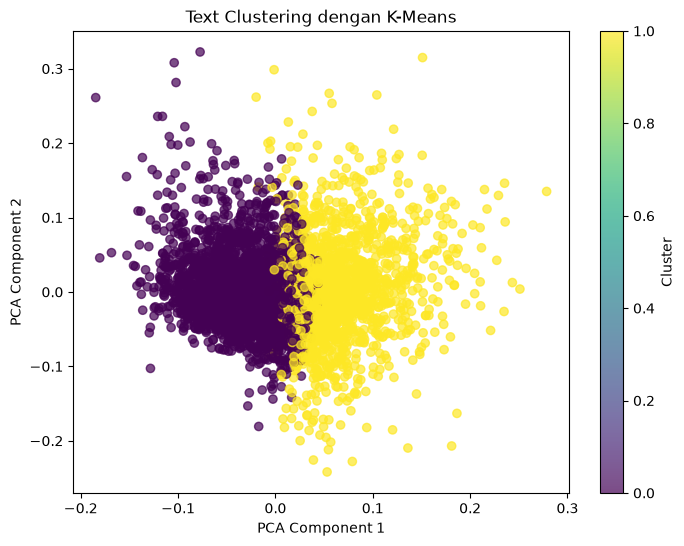

Cluster 0 (3215 film)
Kata teratas: ['world', 'ha', 'new', 'team', 'war', 'film', 'group', 'family', 'set', 'year']
Contoh film : ['Avatar', 'Spectre', 'The Dark Knight Rises', 'John Carter', 'Spider-Man 3']

Cluster 1 (1585 film)
Kata teratas: ['life', 'young', 'ha', 'love', 'woman', 'friend', 'man', 'new', 'story', 'family']
Contoh film : ["Pirates of the Caribbean: At World's End", 'Man of Steel', 'The Chronicles of Narnia: Prince Caspian', 'Pirates of the Caribbean: On Stranger Tides', 'The Amazing Spider-Man']



In [10]:
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()  # Lowercasing
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
    words = word_tokenize(text)  # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words]  # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X = vectorizer.fit_transform(df['clean_text'])

# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

# Interpretasi klaster: kata teratas dan contoh film
terms = vectorizer.get_feature_names_out()
order = kmeans.cluster_centers_.argsort()[:, ::-1]
for i in range(num_clusters):
    print(f"Cluster {i} ({(df['cluster'] == i).sum()} film)")
    print("Kata teratas:", [terms[j] for j in order[i, :10]])
    print("Contoh film :", df[df['cluster'] == i]['title'].head(5).tolist())
    print()